In [1]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

In [2]:
MASKS_DIR = "../data/train_dataset_clean/masks"

In [3]:
CLASS_MAP = {
    (255, 255, 255): "background",                
    (1, 88, 255): "sky",                         
    (156, 76, 30): "rough_trail",                
    (178, 176, 153): "smooth_trail",             
    (128, 255, 0): "traversable_grass",          
    (40, 80, 0): "high_vegetation",              
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",                     
    (255, 0, 0): "obstacle"                      
}

In [4]:
pixel_counts = {v: 0 for v in CLASS_MAP.values()}
total_pixels = 0

for f in tqdm(os.listdir(MASKS_DIR), desc="Analyzing masks"):
    if not f.endswith(".png"):
        continue
    mask = np.array(Image.open(os.path.join(MASKS_DIR, f)).convert("RGB"))
    total_pixels += mask.shape[0] * mask.shape[1]

    # Conta i pixel di ciascun colore (classe)
    unique, counts = np.unique(mask.reshape(-1, 3), axis=0, return_counts=True)
    for rgb, c in zip(unique, counts):
        label = CLASS_MAP.get(tuple(rgb.tolist()))
        if label:
            pixel_counts[label] += c

Analyzing masks: 100%|██████████| 3670/3670 [13:41<00:00,  4.47it/s]


In [5]:
# === Calcola percentuali per ogni classe ===
df_stats = pd.DataFrame(list(pixel_counts.items()), columns=["class", "pixels"])
df_stats["percentage"] = 100 * df_stats["pixels"] / total_pixels

# === Calcola pesi inversi ===
epsilon = 1e-6
df_stats["inv_weight"] = 1 / (df_stats["pixels"] / total_pixels + epsilon)
df_stats["log_inv_weight"] = -np.log(df_stats["pixels"] / total_pixels + epsilon)
df_stats["norm_log_weight"] = df_stats["log_inv_weight"] / df_stats["log_inv_weight"].mean()

# === Mostra risultati ===
print("\n✅ Class distribution and balancing weights:\n")
display(df_stats.round(4))



✅ Class distribution and balancing weights:



,class,pixels,percentage,inv_weight,log_inv_weight,norm_log_weight
0,background,14831408,1.0372,96.4033,4.5685,1.4017
1,sky,404887234,28.3151,3.5317,1.2618,0.3871
2,rough_trail,78813041,5.5117,18.1430,2.8983,0.8892
3,smooth_trail,237728331,16.6251,6.0150,1.7942,0.5505
4,traversable_grass,324266729,22.6770,4.4097,1.4838,0.4553
5,high_vegetation,323626097,22.6322,4.4185,1.4858,0.4559
6,non_traversable_low_vegetation,32365180,2.2634,44.1793,3.7883,1.1623
7,puddle,954359,0.0667,1496.0772,7.3106,2.2430
8,obstacle,12461701,0.8715,114.7331,4.7426,1.4551


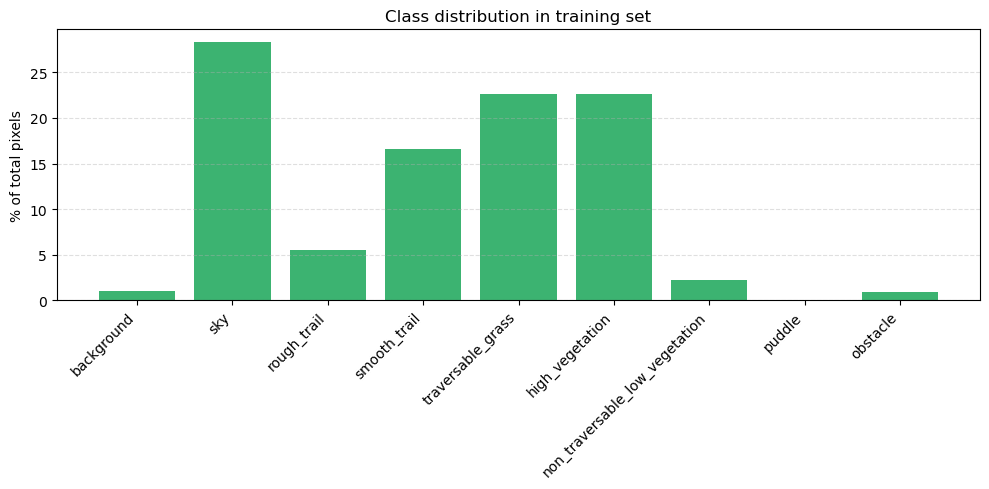

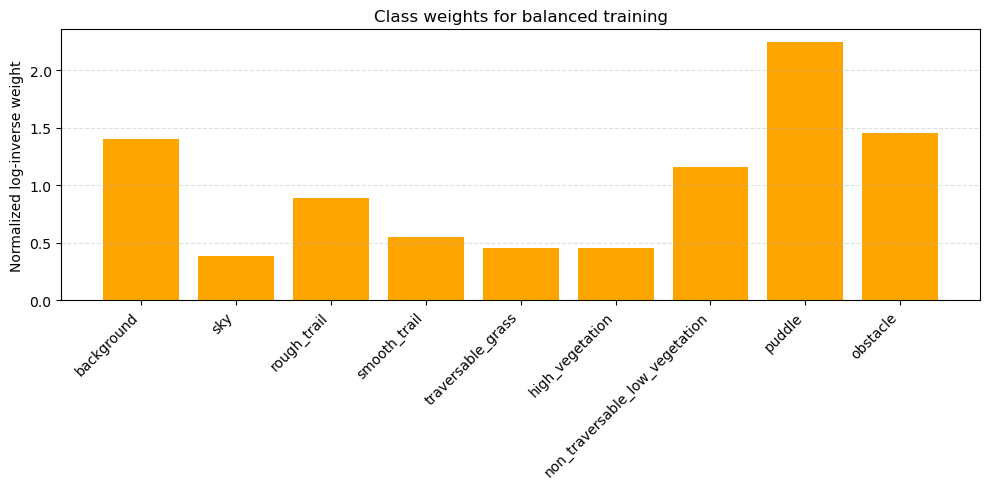

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(df_stats["class"], df_stats["percentage"], color="mediumseagreen")
plt.xticks(rotation=45, ha="right")
plt.ylabel("% of total pixels")
plt.title("Class distribution in training set")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
plt.bar(df_stats["class"], df_stats["norm_log_weight"], color="orange")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Normalized log-inverse weight")
plt.title("Class weights for balanced training")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [12]:
import os

IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

imgs = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith((".jpg", ".png"))])
masks = sorted([f for f in os.listdir(MASK_DIR) if f.lower().endswith(".png")])

removed = 0

for mask in masks:
    # Trova il nome dell’immagine corrispondente
    if mask.startswith("B_segmentation_"):
        img_name = mask.replace("B_segmentation_", "B_rgb_").replace(".png", ".png")
        if img_name not in imgs:
            os.remove(os.path.join(MASK_DIR, mask))
            removed += 1
    else:
        img_name = mask.replace(".png", ".jpg")
        if img_name not in imgs:
            os.remove(os.path.join(MASK_DIR, mask))
            removed += 1

print(f"✅ Maschere totali eliminate: {removed}")
print(f"📁 Cartella aggiornata: {MASK_DIR}")

✅ Maschere totali eliminate: 336
📁 Cartella aggiornata: ../data/train_dataset_clean/masks


In [13]:
import os

IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

imgs = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith((".jpg", ".png"))])
masks = sorted([f for f in os.listdir(MASK_DIR) if f.lower().endswith(".png")])

missing_masks = []
found = 0

for img in imgs:
    if img.startswith("B_rgb_"):
        mask_name = img.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
    else:
        mask_name = img.replace(".jpg", ".png")
    if mask_name in masks:
        found += 1
    else:
        missing_masks.append(img)

print(f"✅ Immagini totali: {len(imgs)}")
print(f"✅ Maschere totali: {len(masks)}")
print(f"🎯 Immagini con maschera corrispondente: {found}")
print(f"⚠️ Immagini senza maschera: {len(missing_masks)}")
print("Esempi mancanti:", missing_masks[:10])

✅ Immagini totali: 3334
✅ Maschere totali: 3334
🎯 Immagini con maschera corrispondente: 3334
⚠️ Immagini senza maschera: 0
Esempi mancanti: []


📟 Using device: mps
🚀 Starting training...


100%|██████████| 334/334 [01:24<00:00,  3.97it/s]


Epoch [1/5] - Loss: 0.8556


100%|██████████| 334/334 [01:22<00:00,  4.04it/s]


Epoch [2/5] - Loss: 0.4345


100%|██████████| 334/334 [01:22<00:00,  4.03it/s]


Epoch [3/5] - Loss: 0.3533


100%|██████████| 334/334 [01:23<00:00,  3.98it/s]


Epoch [4/5] - Loss: 0.3092


100%|██████████| 334/334 [01:22<00:00,  4.06it/s]


Epoch [5/5] - Loss: 0.2848
✅ Training completed!
💾 Model saved as 'unet_trail_final.pth'


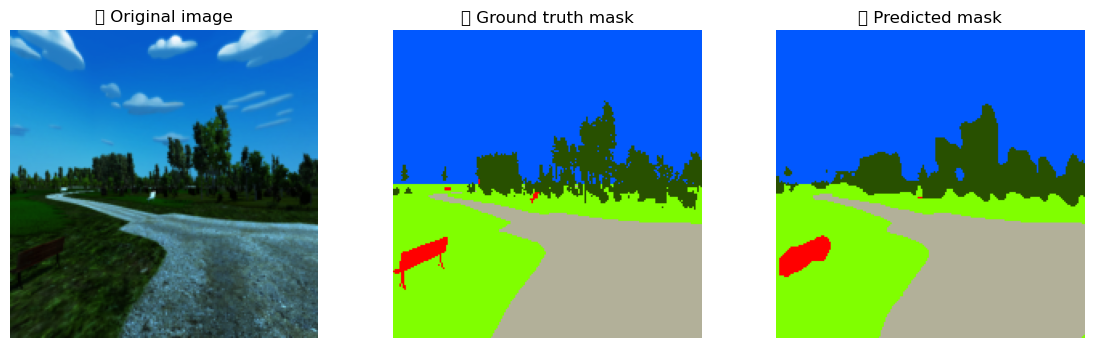

In [18]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt

# === Percorsi dataset ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 8
EPOCHS = 5
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}

# === Dataset personalizzato ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        # Trova la maschera corretta
        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        # Carica immagine e maschera
        image = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path).convert("RGB"))

        # Ridimensiona la maschera
        mask = Image.fromarray(mask).resize((192, 192), Image.NEAREST)
        mask = np.array(mask)

        # Converti i colori in indici
        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mask_idx, dtype=torch.long)

# === Trasformazioni ===
transform = transforms.Compose([
    transforms.Resize((192, 192)),
    transforms.ToTensor(),
])

# === Dataset e DataLoader ===
dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net ===
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi di classe dal tuo df_stats ===
class_weights = torch.tensor([
    1.4017,  # background
    0.3871,  # sky
    0.8892,  # rough_trail
    0.5505,  # smooth_trail
    0.4553,  # traversable_grass
    0.4559,  # high_vegetation
    1.1623,  # non_traversable_low_vegetation
    2.2430,  # puddle
    1.4551   # obstacle
], dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# === Training ===
print("🚀 Starting training...")
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {train_loss/len(train_loader):.4f}")

print("✅ Training completed!")
torch.save(model.state_dict(), "unet_trail_final.pth")
print("💾 Model saved as 'unet_trail_final.pth'")

# === Funzione per colorare le maschere ===
COLOR_MAP = list(CLASS_MAP.keys())

def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

# === Visualizza 5 immagini con predizione ===
model.eval()
with torch.no_grad():
    imgs, masks = next(iter(val_loader))
    imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
    preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
    true_masks = masks.cpu().numpy()

def show_sample(img, true_mask, pred_mask):
    plt.figure(figsize=(14,4))
    plt.subplot(1,3,1)
    plt.imshow(np.transpose(img.cpu().numpy(), (1,2,0)))
    plt.title("🖼️ Original image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(decode_mask(true_mask))
    plt.title("🎯 Ground truth mask")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(decode_mask(pred_mask))
    plt.title("🤖 Predicted mask")
    plt.axis("off")
    plt.show()

for i in range(min(5, len(preds))):
    show_sample(imgs[i], true_masks[i], preds[i])

In [19]:
import numpy as np
from tqdm import tqdm

def compute_iou(pred_mask, true_mask, num_classes):
    """Calcola IoU per ogni classe"""
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        intersection = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)  # classe assente
        else:
            ious.append(intersection / union)
    return ious

# === Calcolo mIoU sul set di validazione ===
model.eval()
ious_all = []

with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Evaluating mIoU"):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        masks_np = masks.cpu().numpy()

        for pred_mask, true_mask in zip(preds, masks_np):
            ious = compute_iou(pred_mask, true_mask, NUM_CLASSES)
            ious_all.append(ious)

# Media delle IoU
ious_all = np.array(ious_all)
mean_iou_per_class = np.nanmean(ious_all, axis=0)
miou = np.nanmean(mean_iou_per_class)

# === Stampa risultati ===
print("\n📊 Mean IoU (mIoU):", round(miou, 4))
print("\nIoU per classe:")
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

Evaluating mIoU: 100%|██████████| 667/667 [00:20<00:00, 31.86it/s]


📊 Mean IoU (mIoU): 0.5058

IoU per classe:
background                         : 0.5339
sky                                : 0.8838
rough_trail                        : 0.3447
smooth_trail                       : 0.8042
traversable_grass                  : 0.8014
high_vegetation                    : 0.7504
non_traversable_low_vegetation     : 0.1440
puddle                             : 0.0000
obstacle                           : 0.2894


📟 Using device: mps


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

🚀 Starting improved training...


100%|██████████| 445/445 [03:14<00:00,  2.29it/s]


Epoch [1/10] - Loss: 0.7732


... (16 outputs left out)

100%|██████████| 445/445 [03:16<00:00,  2.27it/s]


Epoch [10/10] - Loss: 0.2228
✅ Training completed!
💾 Model saved as 'unet_trail_resnet50.pth'


Evaluating mIoU: 100%|██████████| 667/667 [00:37<00:00, 17.65it/s]



📊 Mean IoU (mIoU): 0.495

IoU per classe:
background                         : 0.2852
sky                                : 0.8729
rough_trail                        : 0.3379
smooth_trail                       : 0.8439
traversable_grass                  : 0.8250
high_vegetation                    : 0.7724
non_traversable_low_vegetation     : 0.1748
puddle                             : 0.0000
obstacle                           : 0.3434


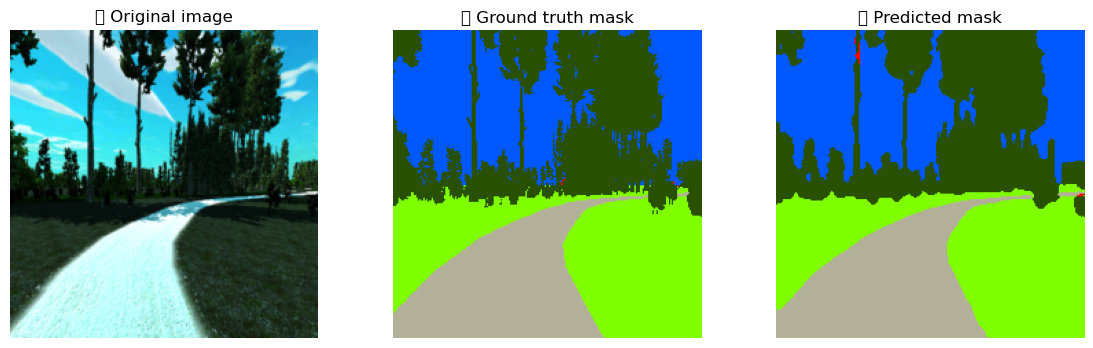

In [20]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt

# === Percorsi dataset ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 6
EPOCHS = 10
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}

COLOR_MAP = list(CLASS_MAP.keys())

# === Dataset ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        image = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path).convert("RGB"))
        mask = Image.fromarray(mask).resize((224, 224), Image.NEAREST)
        mask = np.array(mask)

        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mask_idx, dtype=torch.long)

# === Trasformazioni ===
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net (ResNet50 encoder) ===
model = smp.Unet(
    encoder_name="resnet50",       # 🔥 modello più potente
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi di classe dal df_stats ===
class_weights = torch.tensor([
    1.4017,  # background
    0.3871,  # sky
    0.8892,  # rough_trail
    0.5505,  # smooth_trail
    0.4553,  # traversable_grass
    0.4559,  # high_vegetation
    1.1623,  # non_traversable_low_vegetation
    2.2430,  # puddle
    1.4551   # obstacle
], dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# === Training ===
print("🚀 Starting improved training...")
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {train_loss/len(train_loader):.4f}")

print("✅ Training completed!")
torch.save(model.state_dict(), "unet_trail_resnet50.pth")
print("💾 Model saved as 'unet_trail_resnet50.pth'")

# === Funzione per colorare le maschere ===
def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

# === Calcolo mIoU ===
def compute_iou(pred_mask, true_mask, num_classes):
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        intersection = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(intersection / union)
    return ious

model.eval()
ious_all = []
with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Evaluating mIoU"):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        masks_np = masks.cpu().numpy()
        for pred_mask, true_mask in zip(preds, masks_np):
            ious = compute_iou(pred_mask, true_mask, NUM_CLASSES)
            ious_all.append(ious)

ious_all = np.array(ious_all)
mean_iou_per_class = np.nanmean(ious_all, axis=0)
miou = np.nanmean(mean_iou_per_class)

print("\n📊 Mean IoU (mIoU):", round(miou, 4))
print("\nIoU per classe:")
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

# === Visualizza 5 esempi finali ===
model.eval()
with torch.no_grad():
    imgs, masks = next(iter(val_loader))
    imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
    preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
    true_masks = masks.cpu().numpy()

def show_sample(img, true_mask, pred_mask):
    plt.figure(figsize=(14,4))
    plt.subplot(1,3,1)
    plt.imshow(np.transpose(img.cpu().numpy(), (1,2,0)))
    plt.title("🖼️ Original image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(decode_mask(true_mask))
    plt.title("🎯 Ground truth mask")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(decode_mask(pred_mask))
    plt.title("🤖 Predicted mask")
    plt.axis("off")
    plt.show()

for i in range(min(5, len(preds))):
    show_sample(imgs[i], true_masks[i], preds[i])

📟 Using device: mps
🚀 Starting training with reinforced weights...


100%|██████████| 334/334 [02:04<00:00,  2.69it/s]


Epoch [1/10] - Loss: 0.8802


100%|██████████| 334/334 [01:59<00:00,  2.80it/s]


Epoch [2/10] - Loss: 0.4604


100%|██████████| 334/334 [01:59<00:00,  2.80it/s]


... (13 outputs left out)

100%|██████████| 334/334 [02:02<00:00,  2.72it/s]


Epoch [10/10] - Loss: 0.2356
✅ Training completed!
💾 Model saved as 'unet_trail_weighted.pth'


Evaluating mIoU: 100%|██████████| 667/667 [00:22<00:00, 29.54it/s]



📊 Mean IoU (mIoU): 0.514

IoU per classe:
background                         : 0.5550
sky                                : 0.8802
rough_trail                        : 0.3452
smooth_trail                       : 0.8097
traversable_grass                  : 0.8075
high_vegetation                    : 0.7679
non_traversable_low_vegetation     : 0.1650
puddle                             : 0.0041
obstacle                           : 0.2912


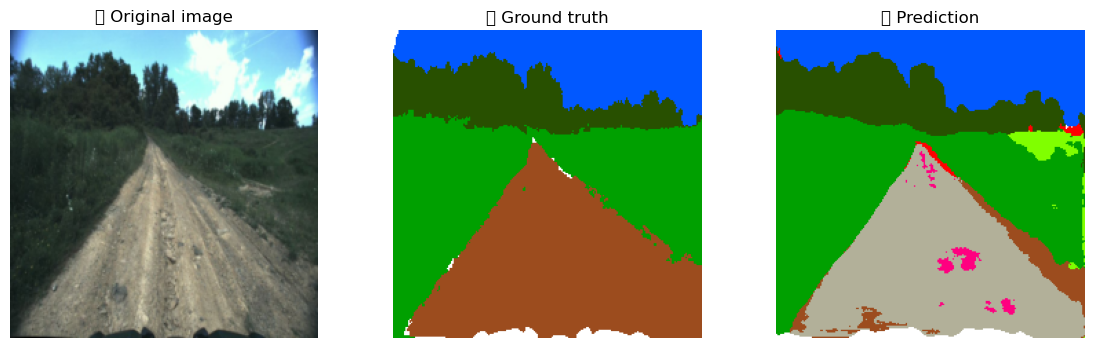

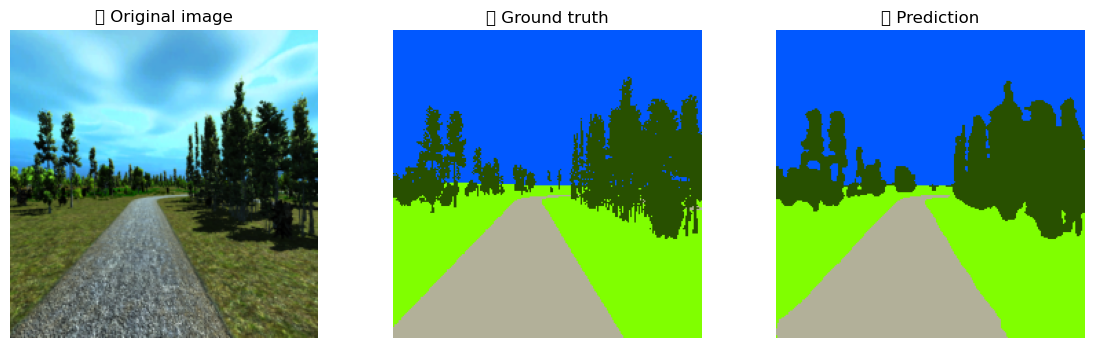

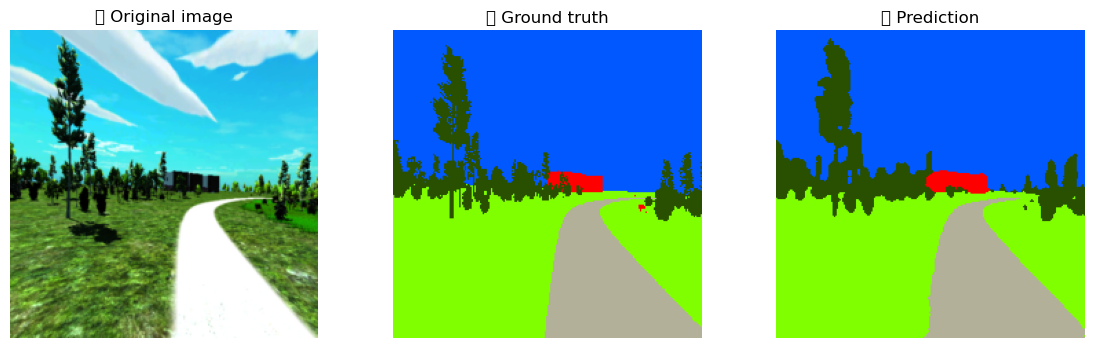

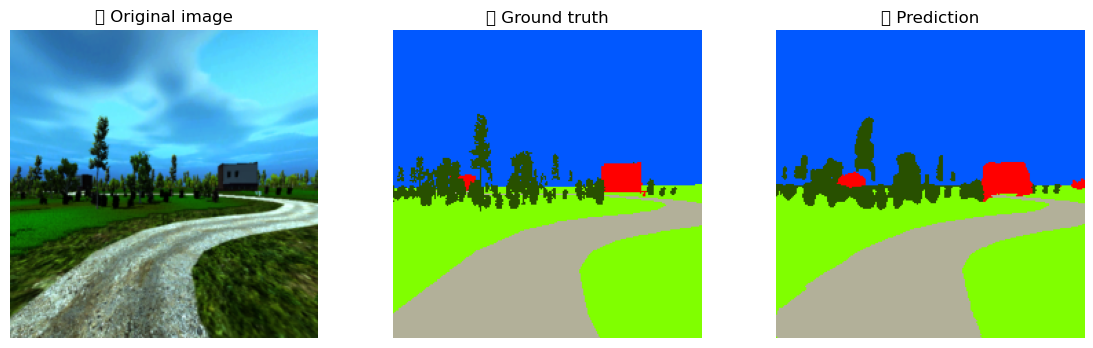

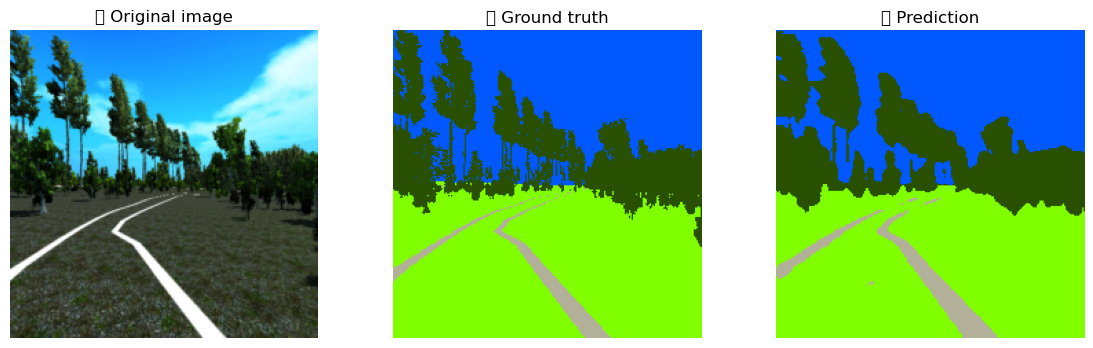

In [21]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt

# === Percorsi ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 8
EPOCHS = 10
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}
COLOR_MAP = list(CLASS_MAP.keys())

# === Dataset ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        image = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path).convert("RGB"))

        mask = Image.fromarray(mask).resize((224, 224), Image.NEAREST)
        mask = np.array(mask)

        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mask_idx, dtype=torch.long)

# === Trasformazioni ===
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# === Dataset e DataLoader ===
dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net ===
model = smp.Unet(
    encoder_name="resnet34",  # resta su U-Net classica
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi di classe (rinforzati per le classi difficili) ===
class_weights = torch.tensor([
    1.4017,  # background
    0.3871,  # sky
    0.8892,  # rough_trail
    0.5505,  # smooth_trail
    0.4553,  # traversable_grass
    0.4559,  # high_vegetation
    1.1623 * 1.5,  # non_traversable_low_vegetation ↑
    2.2430 * 2.5,  # puddle ↑↑
    1.4551 * 1.7   # obstacle ↑↑
], dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# === Funzioni utili ===
def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

def compute_iou(pred_mask, true_mask, num_classes):
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        inter = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(inter / union)
    return ious

# === Training ===
print("🚀 Starting training with reinforced weights...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f}")

print("✅ Training completed!")
torch.save(model.state_dict(), "unet_trail_weighted.pth")
print("💾 Model saved as 'unet_trail_weighted.pth'")

# === Valutazione ===
model.eval()
ious_all = []
with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Evaluating mIoU"):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        masks_np = masks.cpu().numpy()
        for p, t in zip(preds, masks_np):
            ious = compute_iou(p, t, NUM_CLASSES)
            ious_all.append(ious)

ious_all = np.array(ious_all)
mean_iou_per_class = np.nanmean(ious_all, axis=0)
miou = np.nanmean(mean_iou_per_class)

print("\n📊 Mean IoU (mIoU):", round(miou, 4))
print("\nIoU per classe:")
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

# === Visualizza 5 esempi ===
model.eval()
with torch.no_grad():
    for i, (imgs, masks) in enumerate(val_loader):
        if i >= 5:
            break
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        true_masks = masks.cpu().numpy()

        plt.figure(figsize=(14,4))
        plt.subplot(1,3,1)
        plt.imshow(np.transpose(imgs[0].cpu().numpy(), (1,2,0)))
        plt.title("🖼️ Original image")
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(decode_mask(true_masks[0]))
        plt.title("🎯 Ground truth")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(decode_mask(preds[0]))
        plt.title("🤖 Prediction")
        plt.axis("off")
        plt.show()

📟 Using device: mps
🚀 Starting training with reinforced weights...


100%|██████████| 334/334 [02:00<00:00,  2.78it/s]


Epoch [1/10] - Loss: 0.8830


100%|██████████| 334/334 [01:59<00:00,  2.80it/s]


Epoch [2/10] - Loss: 0.4751


100%|██████████| 334/334 [01:59<00:00,  2.80it/s]


... (13 outputs left out)

100%|██████████| 334/334 [02:06<00:00,  2.64it/s]


Epoch [10/10] - Loss: 0.2585
✅ Training completed!
💾 Model saved as 'unet_trail_weighted.pth'


Evaluating mIoU: 100%|██████████| 667/667 [00:22<00:00, 29.83it/s]
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)



📊 Mean IoU (mIoU): 0.5363

IoU per classe:
background                         : 0.6386
sky                                : 0.9009
rough_trail                        : 0.3834
smooth_trail                       : 0.8432
traversable_grass                  : 0.8190
high_vegetation                    : 0.7583
non_traversable_low_vegetation     : 0.1786
puddle                             : 0.0073
obstacle                           : 0.2974


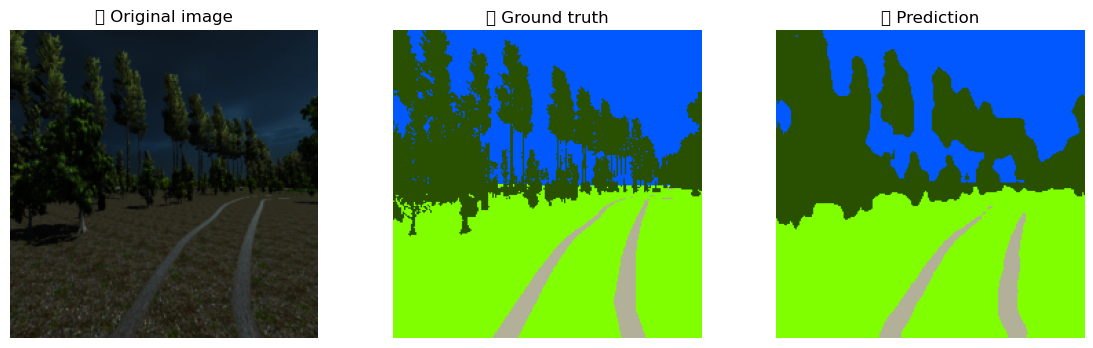

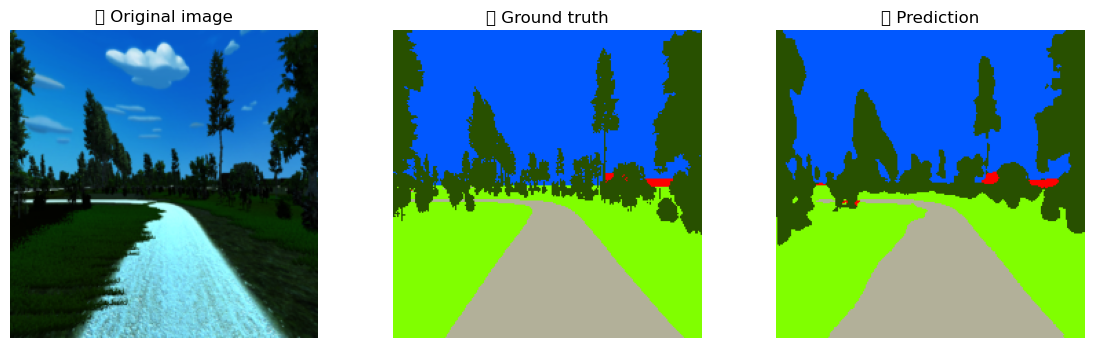

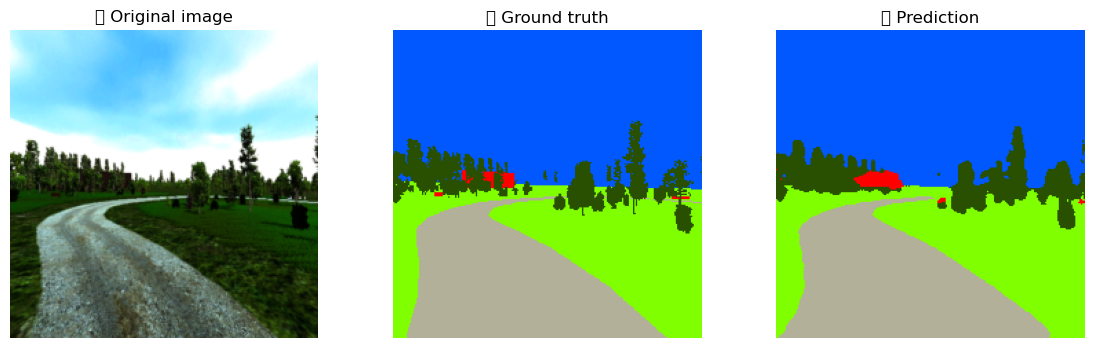

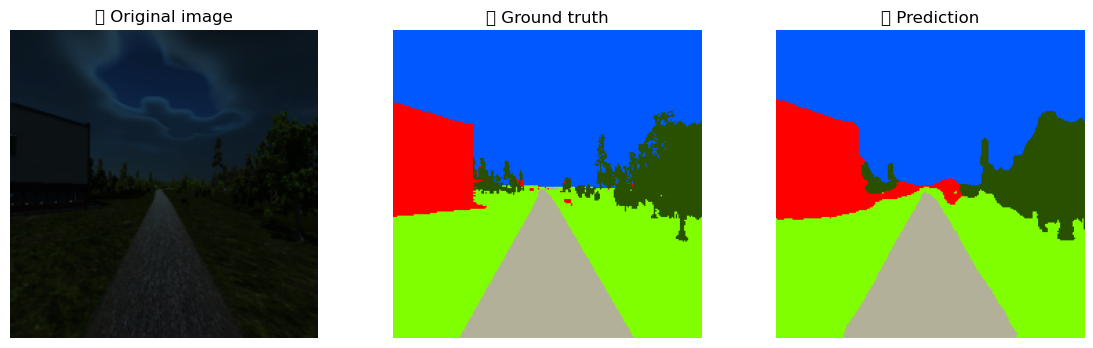

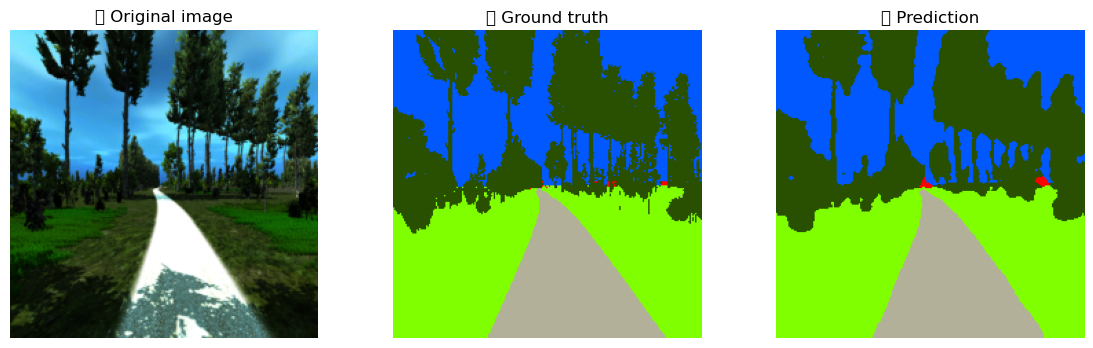

In [22]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt

# === Percorsi ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 8
EPOCHS = 10
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}
COLOR_MAP = list(CLASS_MAP.keys())

# === Dataset ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        image = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path).convert("RGB"))

        mask = Image.fromarray(mask).resize((224, 224), Image.NEAREST)
        mask = np.array(mask)

        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mask_idx, dtype=torch.long)

# === Trasformazioni ===
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# === Dataset e DataLoader ===
dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net ===
model = smp.Unet(
    encoder_name="resnet34",  # resta su U-Net classica
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi di classe (rinforzati per le classi difficili) ===
class_weights = torch.tensor([
    1.4017,      # background
    0.3871,      # sky
    0.8892,      # rough_trail
    0.5505,      # smooth_trail
    0.4553,      # traversable_grass
    0.4559,      # high_vegetation
    1.1623 * 2,  # non_traversable_low_vegetation ↑
    2.2430 * 5.0,  # puddle ↑↑↑↑
    1.4551 * 2.5   # obstacle ↑↑
], dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# === Funzioni utili ===
def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

def compute_iou(pred_mask, true_mask, num_classes):
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        inter = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(inter / union)
    return ious

# === Training ===
print("🚀 Starting training with reinforced weights...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f}")

print("✅ Training completed!")
torch.save(model.state_dict(), "unet_trail_weighted.pth")
print("💾 Model saved as 'unet_trail_weighted.pth'")

# === Valutazione ===
model.eval()
ious_all = []
with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc="Evaluating mIoU"):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        masks_np = masks.cpu().numpy()
        for p, t in zip(preds, masks_np):
            ious = compute_iou(p, t, NUM_CLASSES)
            ious_all.append(ious)

ious_all = np.array(ious_all)
mean_iou_per_class = np.nanmean(ious_all, axis=0)
miou = np.nanmean(mean_iou_per_class)

print("\n📊 Mean IoU (mIoU):", round(miou, 4))
print("\nIoU per classe:")
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

# === Visualizza 5 esempi ===
model.eval()
with torch.no_grad():
    for i, (imgs, masks) in enumerate(val_loader):
        if i >= 5:
            break
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        true_masks = masks.cpu().numpy()

        plt.figure(figsize=(14,4))
        plt.subplot(1,3,1)
        plt.imshow(np.transpose(imgs[0].cpu().numpy(), (1,2,0)))
        plt.title("🖼️ Original image")
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(decode_mask(true_masks[0]))
        plt.title("🎯 Ground truth")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(decode_mask(preds[0]))
        plt.title("🤖 Prediction")
        plt.axis("off")
        plt.show()

📟 Using device: mps


/opt/anaconda3/lib/python3.12/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


🚀 Starting training...


100%|██████████| 334/334 [03:38<00:00,  1.53it/s]


Epoch [1/15] - Loss: 0.9594 - mIoU: 0.3755


100%|██████████| 334/334 [03:30<00:00,  1.59it/s]


... (24 outputs left out)

Epoch [14/15] - Loss: 0.2188 - mIoU: 0.5029


100%|██████████| 334/334 [03:30<00:00,  1.59it/s]


Epoch [15/15] - Loss: 0.2054 - mIoU: 0.5160
✅ Training completed!
💾 Best model saved (mIoU=0.5193)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


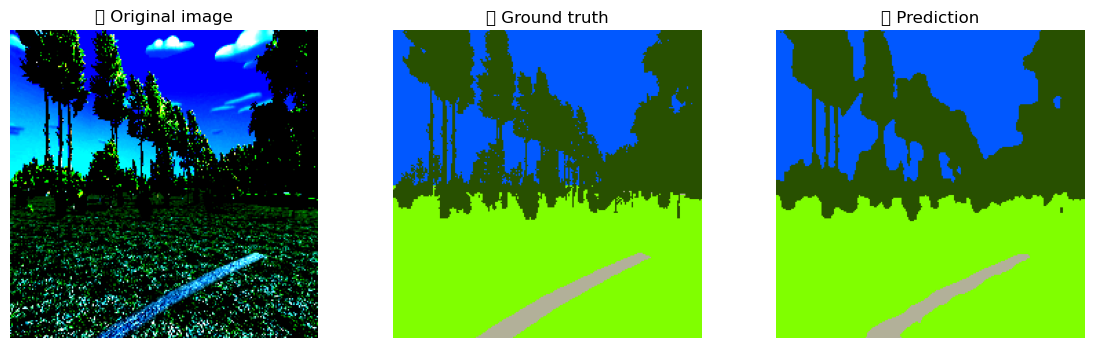

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.186841].


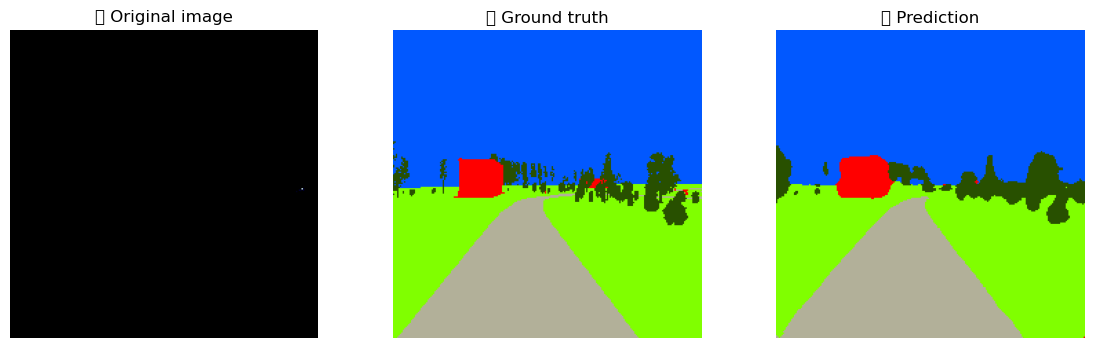

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


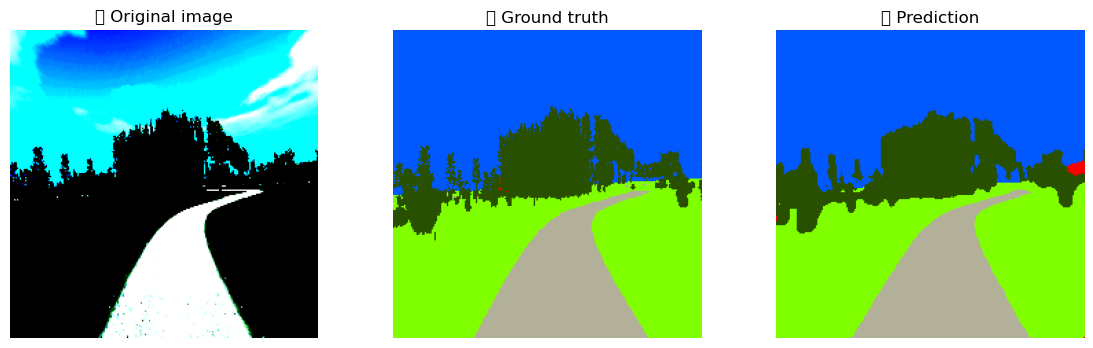

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


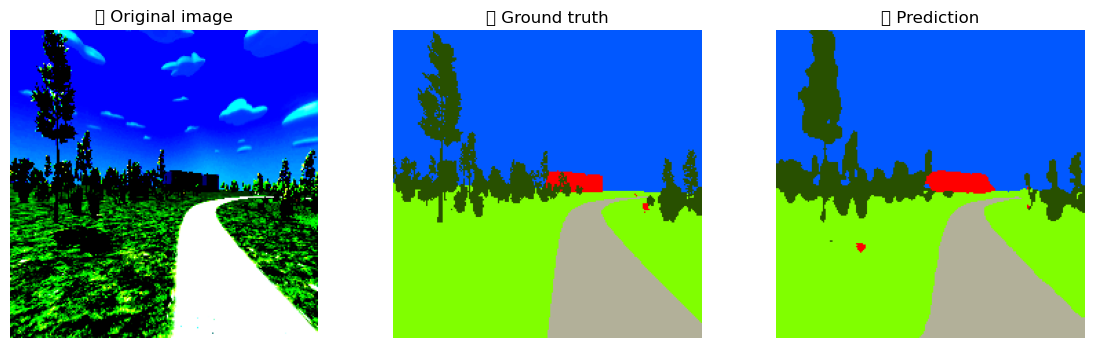

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


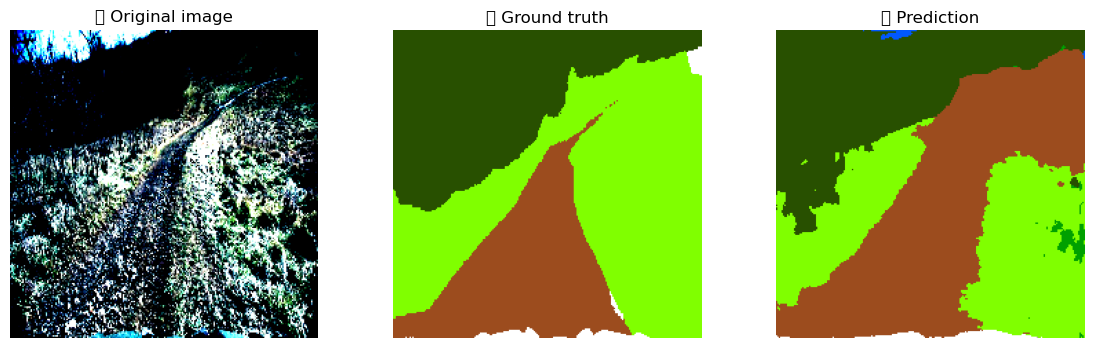

In [23]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

# === Percorsi ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 8
EPOCHS = 15
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}
COLOR_MAP = list(CLASS_MAP.keys())

# === Dataset ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("RGB"))

        # Converti colori in indici
        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            augmented = self.transform(image=image, mask=mask_idx)
            image = augmented["image"]
            mask_idx = augmented["mask"]

        return image, mask_idx

# === Trasformazioni (Albumentations) ===
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomBrightnessContrast(p=0.4),
    A.RandomGamma(p=0.3),
    A.RandomShadow(p=0.3),
    A.RandomRain(p=0.3),
    A.RandomFog(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.4),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# === Dataset e DataLoader ===
dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=train_transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
val_ds.dataset.transform = val_transform

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net (ResNet34) ===
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi di classe rinforzati ===
class_weights = torch.tensor([
    1.4017,  # background
    0.3871,  # sky
    0.8892,  # rough_trail
    0.5505,  # smooth_trail
    0.4553,  # traversable_grass
    0.4559,  # high_vegetation
    1.1623 * 3,  # non_traversable_low_vegetation 
    2.2430 * 10,  # puddle 
    1.4551 * 5   # obstacle 
], dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# === Funzioni utili ===
def compute_iou(pred_mask, true_mask, num_classes):
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        inter = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(inter / union)
    return ious

def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

# === Training con mIoU ===
best_miou = 0
print("🚀 Starting training...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)

    # Valutazione mIoU
    model.eval()
    ious_all = []
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
            masks_np = masks.cpu().numpy()
            for pred_mask, true_mask in zip(preds, masks_np):
                ious = compute_iou(pred_mask, true_mask, NUM_CLASSES)
                ious_all.append(ious)
    ious_all = np.array(ious_all)
    mean_iou_per_class = np.nanmean(ious_all, axis=0)
    miou = np.nanmean(mean_iou_per_class)

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f} - mIoU: {miou:.4f}")

    if miou > best_miou:
        best_miou = miou
        torch.save(model.state_dict(), "unet_trail_best.pth")

print("✅ Training completed!")
print(f"💾 Best model saved (mIoU={best_miou:.4f})")

# === Visualizza 5 esempi ===
model.load_state_dict(torch.load("unet_trail_best.pth"))
model.eval()
with torch.no_grad():
    for i, (imgs, masks) in enumerate(val_loader):
        if i >= 5:
            break
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        true_masks = masks.cpu().numpy()

        plt.figure(figsize=(14,4))
        plt.subplot(1,3,1)
        plt.imshow(np.transpose(imgs[0].cpu().numpy(), (1,2,0)))
        plt.title("🖼️ Original image")
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(decode_mask(true_masks[0]))
        plt.title("🎯 Ground truth")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(decode_mask(preds[0]))
        plt.title("🤖 Prediction")
        plt.axis("off")
        plt.show()

In [24]:
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

background                         : 0.5181
sky                                : 0.9007
rough_trail                        : 0.3967
smooth_trail                       : 0.8253
traversable_grass                  : 0.8388
high_vegetation                    : 0.7628
non_traversable_low_vegetation     : 0.0916
puddle                             : 0.0185
obstacle                           : 0.2914


📟 Using device: mps
🚀 Starting final training (256×256)...


100%|██████████| 445/445 [04:07<00:00,  1.80it/s]


Epoch [1/25] - Loss: 0.8486 - mIoU: 0.3862


100%|██████████| 445/445 [04:02<00:00,  1.83it/s]


Epoch [2/25] - Loss: 0.5344 - mIoU: 0.4542


100%|██████████| 445/445 [04:00<00:00,  1.85it/s]


... (42 outputs left out)

Epoch [24/25] - Loss: 0.1998 - mIoU: 0.5528


100%|██████████| 445/445 [04:04<00:00,  1.82it/s]


Epoch [25/25] - Loss: 0.1978 - mIoU: 0.5532
✅ Training completed!
💾 Best model saved (mIoU=0.5545)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


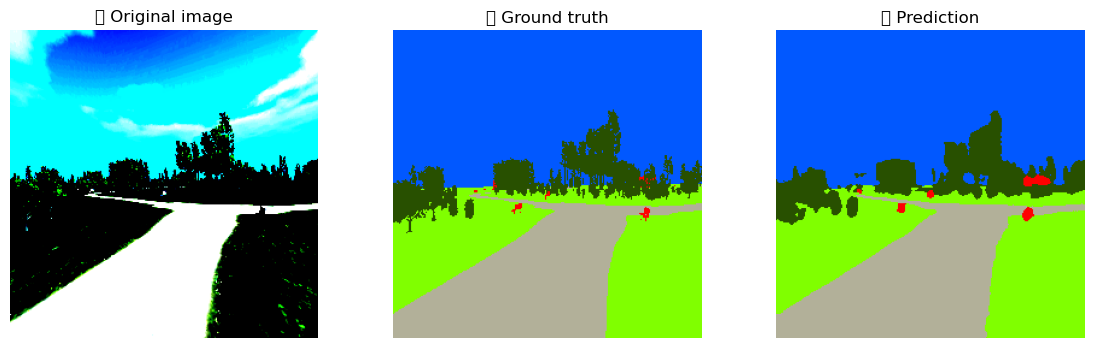

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..0.15266107].


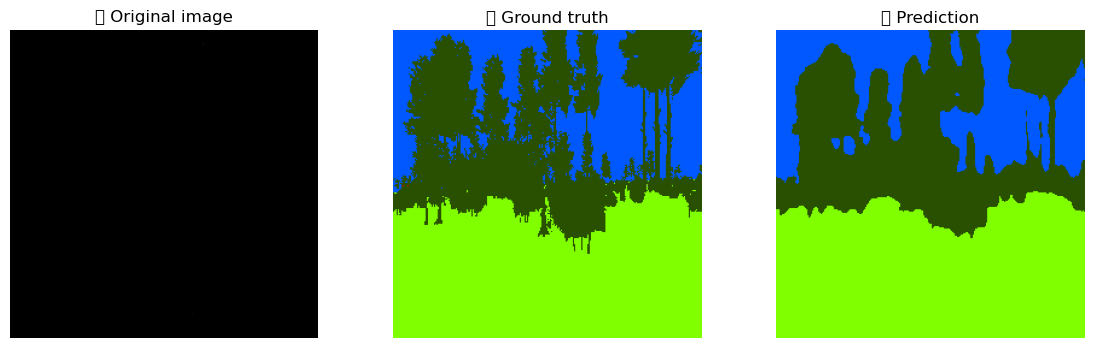

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


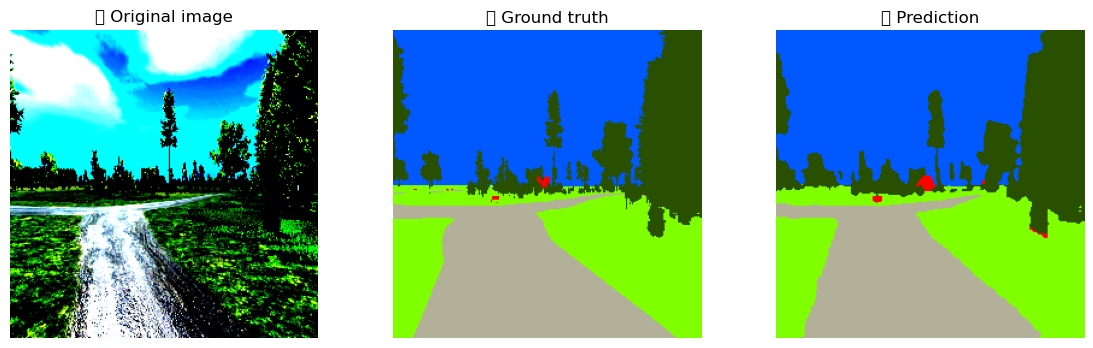

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5702832].


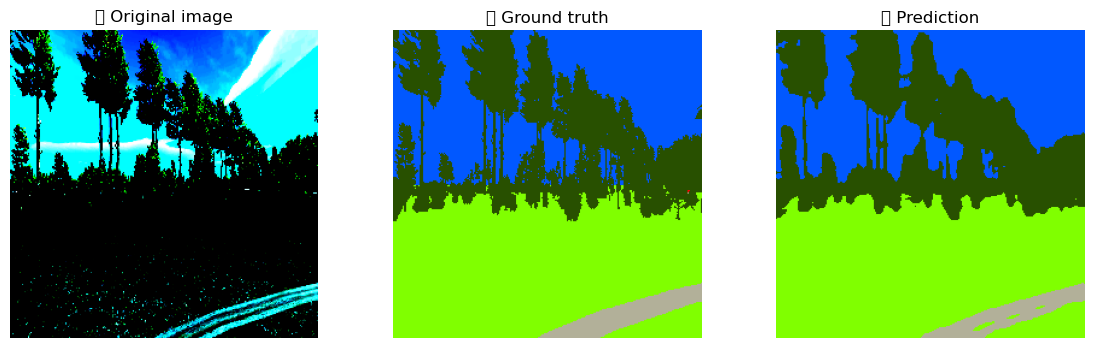

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].


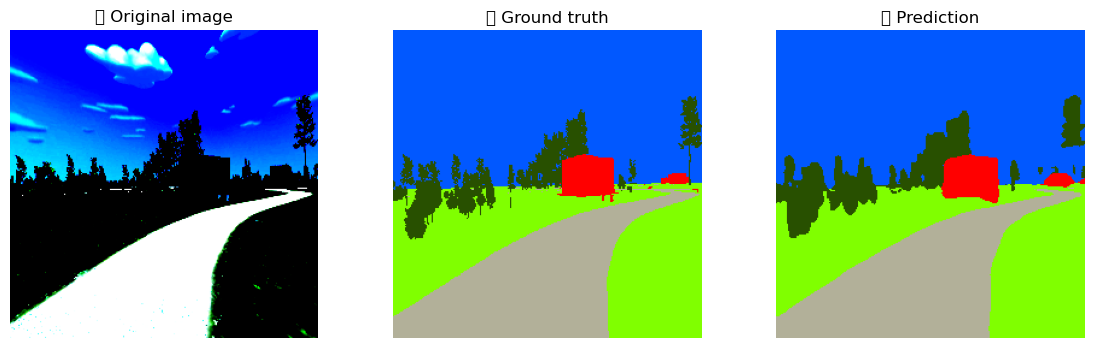

In [28]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import segmentation_models_pytorch as smp
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt

# === Percorsi ===
IMG_DIR = "../data/train_dataset_clean/images"
MASK_DIR = "../data/train_dataset_clean/masks"

# === Parametri ===
BATCH_SIZE = 6
EPOCHS = 25
LR = 1e-4
NUM_CLASSES = 9
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"📟 Using device: {DEVICE}")

# === CLASS_MAP ===
CLASS_MAP = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}
COLOR_MAP = list(CLASS_MAP.keys())

# === Dataset ===
class SegmentationDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = [f for f in os.listdir(img_dir)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)

        if img_name.startswith("B_rgb_"):
            mask_name = img_name.replace("B_rgb_", "B_segmentation_").replace(".jpg", ".png")
        else:
            mask_name = img_name.replace(".jpg", ".png")

        mask_path = os.path.join(self.mask_dir, mask_name)
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"❌ Mask not found for {img_name}: {mask_path}")

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("RGB"))

        # Converti colori in indici
        unique_colors = list(CLASS_MAP.keys())
        mask_idx = np.zeros(mask.shape[:2], dtype=np.int64)
        for i, color in enumerate(unique_colors):
            mask_idx[np.all(mask == color, axis=-1)] = i

        if self.transform:
            augmented = self.transform(image=image, mask=mask_idx)
            image = augmented["image"]
            mask_idx = augmented["mask"]

        return image, mask_idx

# === Augmentation potenziata ===
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomBrightnessContrast(p=0.5),
    A.RandomGamma(p=0.5),
    A.RandomShadow(p=0.5),
    A.RandomRain(p=0.5),
    A.RandomFog(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# === Dataset e DataLoader ===
dataset = SegmentationDataset(IMG_DIR, MASK_DIR, transform=train_transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
val_ds.dataset.transform = val_transform

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# === Modello U-Net (ResNet34) ===
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

# === Pesi rinforzati (finale) ===
class_weights = torch.tensor([
    1.4017,        # background
    0.3871,        # sky
    0.8892,        # rough_trail
    0.5505,        # smooth_trail
    0.4553,        # traversable_grass
    0.4559,        # high_vegetation
    1.1623 * 5.0,  # low vegetation ↑↑↑
    2.2430 * 15.0, # puddle ↑↑↑↑↑↑
    1.4551 * 8.0   # obstacle ↑↑↑↑
], dtype=torch.float32).to(DEVICE)

# === Loss ibrida (CrossEntropy + Dice) ===
def dice_loss(logits, targets, eps=1e-6, num_classes=9):
    probs = torch.softmax(logits, dim=1)
    one_hot = torch.zeros_like(probs).scatter_(1, targets.unsqueeze(1), 1)
    dims = (0,2,3)
    inter = (probs * one_hot).sum(dims)
    union = probs.sum(dims) + one_hot.sum(dims)
    dice = (2*inter + eps) / (union + eps)
    return 1 - dice.mean()

ce = nn.CrossEntropyLoss(weight=class_weights)
def mixed_loss(logits, targets, alpha=0.7):
    return alpha*ce(logits, targets) + (1-alpha)*dice_loss(logits, targets)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

# === Funzioni utili ===
def compute_iou(pred_mask, true_mask, num_classes):
    ious = []
    for cls in range(num_classes):
        pred = (pred_mask == cls)
        true = (true_mask == cls)
        inter = np.logical_and(pred, true).sum()
        union = np.logical_or(pred, true).sum()
        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(inter / union)
    return ious

def decode_mask(mask_idx):
    color_mask = np.zeros((*mask_idx.shape, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_MAP):
        color_mask[mask_idx == idx] = color
    return color_mask

# === Training con scheduler ===
best_miou = 0
patience, counter = 5, 0
print("🚀 Starting final training (256×256)...")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for imgs, masks in tqdm(train_loader):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = mixed_loss(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)

    # === Validation ===
    model.eval()
    ious_all = []
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
            masks_np = masks.cpu().numpy()
            for pred_mask, true_mask in zip(preds, masks_np):
                ious = compute_iou(pred_mask, true_mask, NUM_CLASSES)
                ious_all.append(ious)

    ious_all = np.array(ious_all)
    mean_iou_per_class = np.nanmean(ious_all, axis=0)
    miou = np.nanmean(mean_iou_per_class)

    # Aggiorna scheduler e stampa eventuale variazione LR
    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(miou)
    new_lr = optimizer.param_groups[0]['lr']
    if new_lr != old_lr:
        print(f"🔻 Learning rate ridotto: {old_lr:.2e} → {new_lr:.2e}")

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f} - mIoU: {miou:.4f}")

    if miou > best_miou:
        best_miou = miou
        torch.save(model.state_dict(), "unet_trail_256_best.pth")
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("⏹️ Early stopping: no improvement.")
            break

print("✅ Training completed!")
print(f"💾 Best model saved (mIoU={best_miou:.4f})")

# === Visualizza 5 esempi finali ===
model.load_state_dict(torch.load("unet_trail_256_best.pth"))
model.eval()
with torch.no_grad():
    for i, (imgs, masks) in enumerate(val_loader):
        if i >= 5: break
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        true_masks = masks.cpu().numpy()

        plt.figure(figsize=(14,4))
        plt.subplot(1,3,1)
        plt.imshow(np.transpose(imgs[0].cpu().numpy(), (1,2,0)))
        plt.title("🖼️ Original image")
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(decode_mask(true_masks[0]))
        plt.title("🎯 Ground truth")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(decode_mask(preds[0]))
        plt.title("🤖 Prediction")
        plt.axis("off")
        plt.show()

In [29]:
for cls_name, iou in zip(CLASS_MAP.values(), mean_iou_per_class):
    print(f"{cls_name:35s}: {iou:.4f}")

background                         : 0.6560
sky                                : 0.9062
rough_trail                        : 0.4038
smooth_trail                       : 0.8447
traversable_grass                  : 0.8350
high_vegetation                    : 0.7858
non_traversable_low_vegetation     : 0.1280
puddle                             : 0.0625
obstacle                           : 0.3571
